Title: ERA5_SMARD_Comparison_yearly.ipynb

Purpose: Compare output from SEM (with ERA5 climate data) with SMARD data (Data from German TSOs) to validate the model

This is the version with yearly data and the new (optimized) model

Author: Onno Nennecke on 29.04.2025 Modified: 11.07.2026

Input data: 

- ERA5 Residual Load Timeseries
    - This file lies here: /climca/people/onennecke/model_output/not_bias_corrected/full_year/ERA5_timeseries_wwd.nc
    - This file lies here: /climca/people/onennecke/model_output/not_bias_corrected/full_year/ERA5_timeseries_week.nc
- SMARD Production and demand Timeseries
    - This file lies here: /home/onennecke/SMARD_data/Realisierte_Erzeugung_201501010000_202505010000_Tag.csv
    - This file lies here: /home/onennecke/SMARD_data/Realisierter_Stromverbrauch_201501010000_202505010000_Tag.csv

Output data:

- Evaluation Scatter Plots
    - These files lie here: /home/onennecke/Code/Figures/
- Evaluation Demand Plots
    - These files lie here: /home/onennecke/Code/Figures/

In [1]:
# Importing libraries
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D
import matplotlib.dates as mdates
from sklearn.linear_model import LinearRegression
import seaborn as sns
from scipy import stats
from scipy.stats import pearsonr
# import scipy.ndimage as ndimage
# import os
# import glob

# Importing custom functions
import Functions.demand as demand

In [2]:
ERA5_dataset_wwd = xr.open_dataset('/climca/people/onennecke/model_output/not_bias_corrected/ERA5_yearly/ERA5_timeseries_wwd_yearly.nc')
ERA5_dataset = xr.open_dataset('/climca/people/onennecke/model_output/not_bias_corrected/ERA5_yearly/ERA5_hist_timeseries_yearly.nc')

ERA5_dataset.load()

<xarray.Dataset> Size: 321kB
Dimensions:        (time: 3650)
Coordinates:
  * time           (time) datetime64[ns] 29kB 2015-01-01 ... 2024-12-31
    crs            int64 8B 4326
    gridtype       <U6 24B 'lonlat'
    ESM            <U4 16B 'ERA5'
    run            <U4 16B 'hist'
    ESM_run        <U9 36B 'ERA5_hist'
    country        float64 8B 9.0
    period         <U4 16B 'week'
Data variables:
    temp           (time) float64 29kB 1.323 3.335 2.591 ... 0.7396 0.4142
    demand         (time) float64 29kB 1.504e+03 1.479e+03 ... 1.515e+03
    sfcWind        (time) float32 15kB 7.507 11.86 9.267 ... 6.159 8.049 8.775
    rsds           (time) float32 15kB 30.54 19.51 17.85 ... 28.84 26.3 31.92
    tas            (time) float32 15kB 1.771 3.587 3.046 ... 0.2238 1.512 1.194
    tasmax         (time) float32 15kB 3.431 5.871 4.704 ... 2.446 2.709 3.361
    wind_off_prod  (time) float64 29kB 81.14 81.17 81.17 ... 140.7 221.1 221.1
    wind_on_prod   (time) float64 29kB 388.2 796.9 559.3 ... 349.6 783.9 831.2
    solar_prod     (time) float64 29kB 21.88 10.73 10.6 ... 53.04 48.64 59.86
    total_prod     (time) float64 29kB 491.2 888.8 651.0 ... 1.054e+03 1.112e+03
    Netto          (time) float64 29kB -1.012e+03 -589.9 ... -457.1 -402.6
    Residual_load  (time) float64 29kB 1.012e+03 589.9 836.8 ... 457.1 402.6

### Load SMARD data

In [3]:
SMARD_data_prod = pd.read_csv('/home/onennecke/SMARD_data/Realisierte_Erzeugung_201501010000_202505010000_Tag.csv', sep=';', decimal=',', thousands='.')
SMARD_data_demand = pd.read_csv('/home/onennecke/SMARD_data/Realisierter_Stromverbrauch_201501010000_202505010000_Tag.csv', sep=';', decimal=',', thousands='.')

In [4]:

date = pd.to_datetime(SMARD_data_prod['Datum von'].astype(str).str.zfill(8), format='%d%m%Y')
demand_sm = SMARD_data_demand['Netzlast [MWh] Berechnete Auflösungen']
wind_off_prod = SMARD_data_prod['Wind Offshore [MWh] Berechnete Auflösungen']
wind_on_prod = SMARD_data_prod['Wind Onshore [MWh] Berechnete Auflösungen']
solar_prod = SMARD_data_prod['Photovoltaik [MWh] Berechnete Auflösungen']
total_prod = wind_off_prod + wind_on_prod + solar_prod
residual_load = demand_sm - total_prod

df = pd.DataFrame({
    'date': date,
    'demand_SMARD': demand_sm / 1000,  # Convert to GWh
    'wind_offshore_SMARD': wind_off_prod / 1000,  # Convert to GWh
    'wind_onshore_SMARD': wind_on_prod / 1000,  # Convert to GWh
    'solar_SMARD': solar_prod / 1000,  # Convert to GWh
    'total_production_SMARD': total_prod / 1000,  # Convert to GWh
    'residual_load_SMARD': residual_load / 1000,  # Convert to GWh
})


In [5]:
# Cut data to the same time period as ERA5 data (2015-2024)
df = df[(df['date'] >= '2015-01-01') & (df['date'] <= '2024-12-31')]
# Remove leap days
df = df[~((df['date'].dt.month == 2) & (df['date'].dt.day == 29))]
df

,date,demand_SMARD,wind_offshore_SMARD,wind_onshore_SMARD,solar_SMARD,total_production_SMARD,residual_load_SMARD
0,2015-01-01,1096.85275,12.50850,298.79175,17.08025,328.38050,768.47225
1,2015-01-02,1288.91475,10.32925,591.62075,7.75900,609.70900,679.20575
2,2015-01-03,1213.30950,12.11950,457.04350,7.23475,476.39775,736.91175
3,2015-01-04,1177.89600,11.53850,379.02950,19.98250,410.55050,767.34550
4,2015-01-05,1425.92750,7.74550,219.62350,26.52225,253.89125,1172.03625
...,...,...,...,...,...,...,...
3648,2024-12-27,1155.15125,2.94125,46.42200,61.20575,110.56900,1044.58225
3649,2024-12-28,1150.65975,22.34775,31.44225,61.08850,114.87850,1035.78125
3650,2024-12-29,1179.16200,97.29825,257.39450,39.71900,394.41175,784.75025
3651,2024-12-30,1278.28500,61.18675,534.34725,22.92750,618.46150,659.82350


### Combine both datasets

In [6]:
df['sfcWind'] = ERA5_dataset['sfcWind'].values
df['rsds'] = ERA5_dataset['rsds'].values
df['tas'] = ERA5_dataset['tas'].values
df['tasmax'] = ERA5_dataset['tasmax'].values
df['temp_ERA5'] = ERA5_dataset['temp'].values
df['demand_ERA5_wwd'] = ERA5_dataset_wwd['demand'].values
df['demand_ERA5'] = ERA5_dataset['demand'].values
df['RL_ERA5'] = ERA5_dataset['Residual_load']

df['wind_offshore_ERA5'] = ERA5_dataset['wind_off_prod'].values
df['wind_onshore_ERA5'] = ERA5_dataset['wind_on_prod'].values
df['solar_ERA5'] = ERA5_dataset['solar_prod'].values
df['total_production_ERA5'] = df['wind_offshore_ERA5'] + df['wind_onshore_ERA5'] + df['solar_ERA5']
df['total_production_ERA5_check'] = ERA5_dataset['total_prod'].values

In [7]:
# Add weekday or weekend
df['weekday'] = df['date'].dt.dayofweek + 1
df['period'] = np.where(df['weekday'] <= 5, 'Weekday', 'Weekend')

In [8]:
# Define national fixed-date holidays (month, day)
fixed_holidays = [
    (1, 1),   # New Year's Day
    (5, 1),   # Labor Day
    (10, 3),  # German Unity Day
]

# Start by setting all to 'other'
df['special'] = df['period'].copy()

# Summer
df.loc[(df['date'].dt.month == 7) & (df['date'].dt.day >= 15), 'special'] = 'summer'
df.loc[(df['date'].dt.month == 8) & (df['date'].dt.day <= 15), 'special'] = 'summer'


# Christmas period (Dec 20–31)
df.loc[(df['date'].dt.month == 12) & (df['date'].dt.day >= 23), 'special'] = 'christmas'

# Fixed-date holidays
is_fixed_holiday = df['date'].dt.month.astype(str).str.zfill(2) + '-' + df['date'].dt.day.astype(str).str.zfill(2)
fixed_strs = [f"{m:02d}-{d:02d}" for m, d in fixed_holidays]
df.loc[is_fixed_holiday.isin(fixed_strs), 'special'] = 'holiday'

## Make plots to compare the datasets

### Production

In [13]:
def plot_all(df, setlim=False, maintitle=None):
    rows = [
        "wind_onshore",
        # 'wind_onshore_cor',
        "wind_offshore",
        # "wind_offshore_cor",
        "solar",
        # "solar_cor",
        "total_production",
        # "total_production_cor"
    ]
    cols = ["whole_year", "winter", 'perc']

    # Create empty DataFrame (filled with NaN)
    metrics = pd.DataFrame(index=rows, columns=cols)
    
    # --- Make all text bigger (global defaults) ---

    mpl.rcParams.update({
        'font.size': 14+2,             # base font size (affects legends, labels, etc. unless overridden)
        'axes.titlesize': 18+2,        # axes title
        'axes.labelsize': 16+2,        # x/y labels
        'xtick.labelsize': 14+2,       # x tick labels
        'ytick.labelsize': 14+2,       # y tick labels
        'legend.fontsize': 16+2,       # legend text
        'figure.titlesize': 20+2,      # figure title (if used)
    })

    fig, axs = plt.subplots(2, 2, figsize=(16, 12))
    if maintitle:
        fig.suptitle(maintitle, fontsize=22, fontweight='bold')
    plot_specs = [
        ('wind_onshore_SMARD', 'wind_onshore_ERA5', 'Onshore Wind Production'),
        ('wind_offshore_SMARD', 'wind_offshore_ERA5', 'Offshore Wind Production'),
        ('solar_SMARD', 'solar_ERA5', 'Solar Production'),
        ('total_production_SMARD', 'total_production_ERA5', 'Total Renewable Production')
    ]

    subplot_labels = ['(a)', '(b)', '(c)', '(d)']

    for idx, (ax, (col_smard, col_era5, title)) in enumerate(zip(axs.flat, plot_specs)):
        top = col_smard[0:-6]
        # top_cor = col_smard[0:-6] + '_cor'

        sns.scatterplot(x=col_smard, y=col_era5, data=df, alpha=0.6, ax=ax)
        
        # Regression line
        sns.regplot(x=col_smard, y=col_era5, data=df, scatter=False, color='black',
                    line_kws={'linewidth': 1.5, 'alpha': 0.7}, ax=ax)
        
        # 1:1 line
        min_val = min(df[col_smard].min(), df[col_era5].min())
        max_val = max(df[col_smard].max(), df[col_era5].max())
        ax.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--')

        # Adjust axes
        xrange = df[col_smard].max() - df[col_smard].min()
        min_ERA5 = df[col_era5].min()
        max_ERA5 = df[col_era5].max()
        yrange_ERA5 = max_ERA5 - min_ERA5
        ax.set_xlim(df[col_smard].min() - xrange * 0.03, df[col_smard].max() + xrange * 0.03)
        ax.set_ylim(min_ERA5 - xrange * 0.03, max_ERA5 + xrange * 0.03)
        
        if setlim:
            ax.set_ylim(0, yrange_ERA5/4)
            ax.set_xlim(0, yrange_ERA5/4)


        # Metrics
        r, _ = pearsonr(df[col_smard], df[col_era5])
        rmse = np.sqrt(np.mean((df[col_smard] - df[col_era5])**2))
        rrmse = rmse / df[col_smard].mean()
        metrics.loc[top, 'whole_year'] = rmse
        metrics.loc[top, 'rrmse'] = rrmse
        # metrics.loc[top_cor, 'whole_year'] = rmse_corrected

        # Plot labels, titles (made larger)
        ax.set_xlabel(f'{title}\n- SMARD (GWh/day)')
        ax.set_ylabel(f'{title}\n- SEM (GWh/day)')
        ax.set_title(subplot_labels[idx], loc='left', fontweight='bold')
        ax.grid(True, linestyle='--', alpha=0.3)

        textstr = '\n'.join((
                f'RMSE = {rmse:.2f}',
                f'rRMSE = {rrmse:.2f}',
                f'Pearson r = {r:.2f}'
            ))
        ax.text(0.98, 0.03, textstr, transform=ax.transAxes,
                va='bottom', ha='right',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))

    # Create a common legend
    legend_elements = [
        Line2D([0], [0], linestyle='--', color='red', label='1:1 Line'),
        Line2D([0], [0], linestyle='-', color='black', label='Regression Line'),
        Line2D([0], [0], marker='o', color='w', markerfacecolor='blue', label='Data Points', alpha=0.6),
        # Line2D([0], [0], marker='o', color='w', markerfacecolor='orange', label='Corrected Data Points', alpha=0.6),
    ]

    # Place common legend below all subplots (fontsize increased slightly)
    fig.legend(handles=legend_elements, loc='lower center', ncol=4, frameon=True, bbox_to_anchor=(0.5, 0))

    plt.tight_layout(rect=[0, 0.05, 1, 1])  # leave space for legend

    # Save the figure
    # plt.savefig('/home/onennecke/Code/Figures/Mod_eval_scatterplt.png', dpi=300, bbox_inches='tight')
    plt.show()


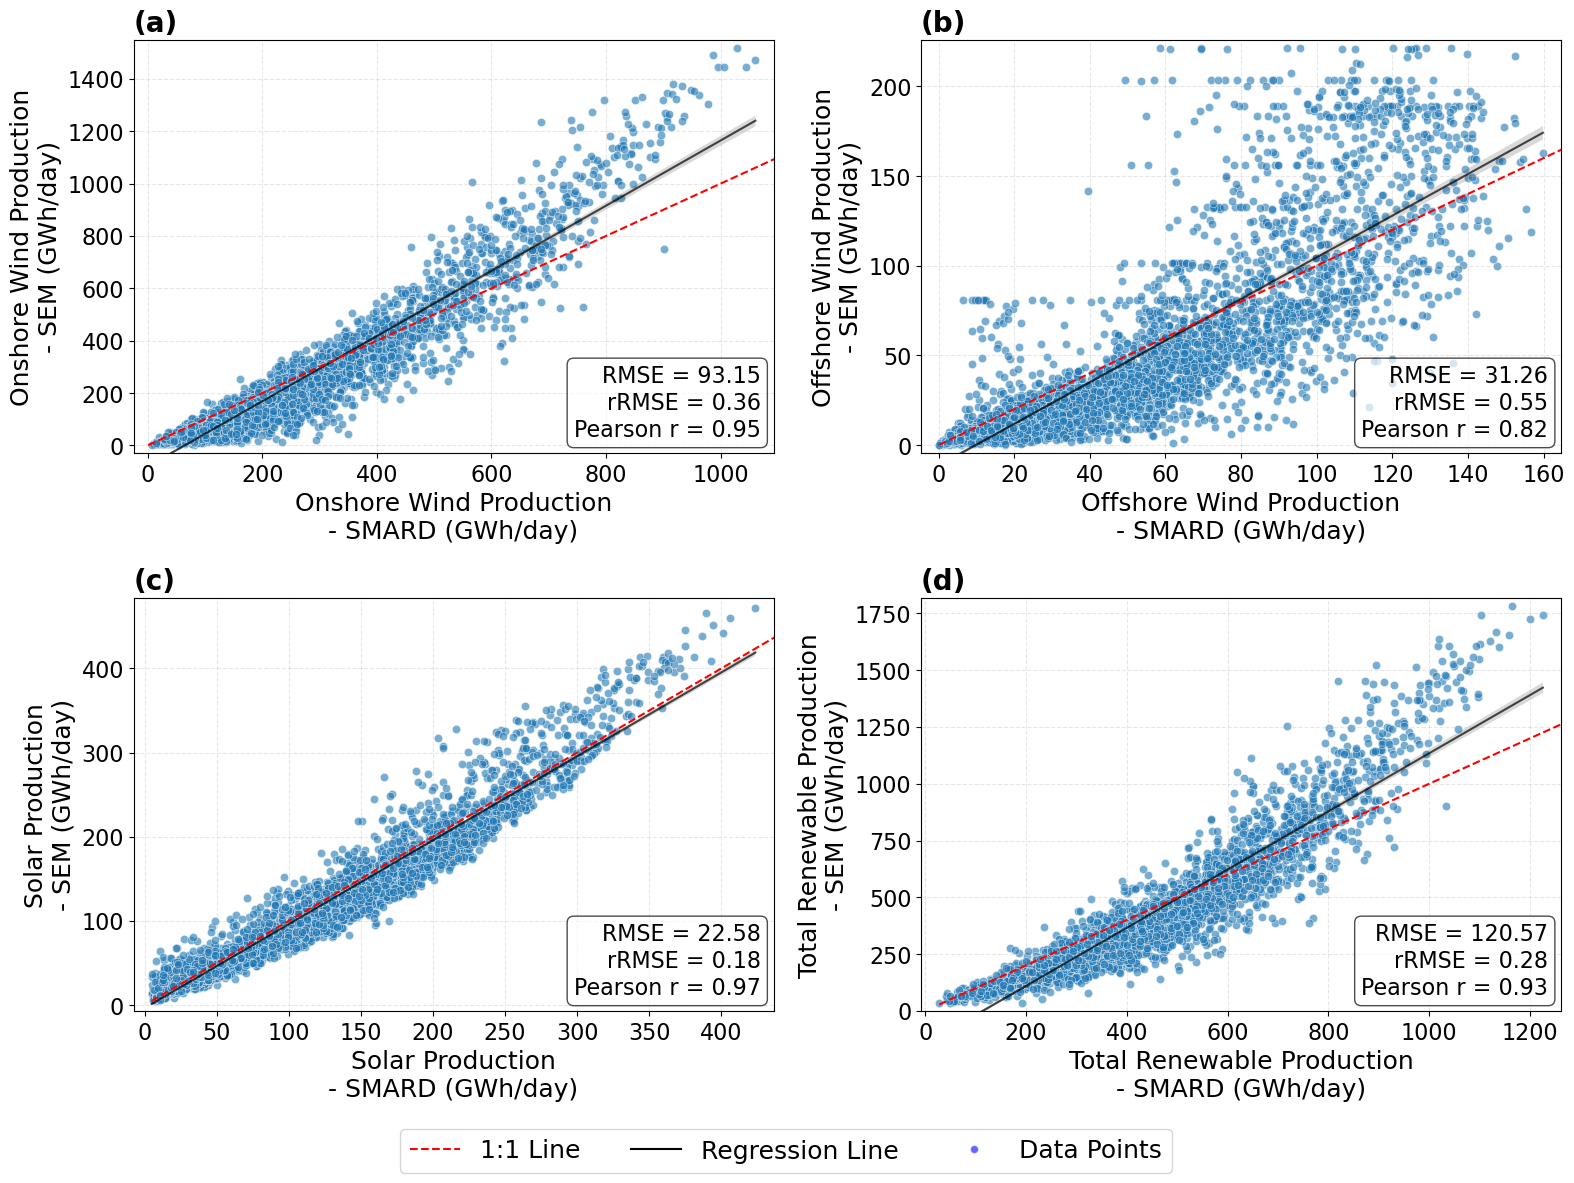

In [14]:
plot_all(df, setlim=False)

### Same plot with OM data included

In [15]:
ERA5_dataset_OM = xr.open_dataset('/climca/people/onennecke/model_output/not_bias_corrected/MA_old_model/full_year/ERA5_hist_timeseries_yearly_new.nc')
ERA5_dataset_OM.load()

<xarray.Dataset> Size: 321kB
Dimensions:        (time: 3650)
Coordinates:
  * time           (time) datetime64[ns] 29kB 2015-01-01 ... 2024-12-31
    crs            int64 8B 4326
    gridtype       <U6 24B 'lonlat'
    ESM            <U4 16B 'ERA5'
    run            <U4 16B 'hist'
    ESM_run        <U9 36B 'ERA5_hist'
    country        float64 8B 9.0
    period         <U4 16B 'week'
Data variables:
    temp           (time) float64 29kB 1.323 3.335 2.591 ... 0.7396 0.4142
    demand         (time) float64 29kB 1.504e+03 1.479e+03 ... 1.515e+03
    sfcWind        (time) float32 15kB 7.507 11.86 9.267 ... 6.159 8.049 8.775
    rsds           (time) float32 15kB 30.54 19.51 17.85 ... 28.84 26.3 31.92
    tas            (time) float32 15kB 1.771 3.587 3.046 ... 0.2238 1.512 1.194
    tasmax         (time) float32 15kB 3.431 5.871 4.704 ... 2.446 2.709 3.361
    wind_off_prod  (time) float64 29kB 81.17 81.17 81.17 ... 179.2 221.1 221.1
    wind_on_prod   (time) float64 29kB 273.2 674.1 430.9 ... 216.6 592.8 602.7
    solar_prod     (time) float64 29kB 32.74 17.38 16.65 ... 78.49 72.3 91.06
    total_prod     (time) float64 29kB 387.1 772.6 528.7 ... 474.3 886.3 914.8
    Netto          (time) float64 29kB -1.116e+03 -706.0 ... -624.5 -600.0
    Residual_load  (time) float64 29kB 1.116e+03 706.0 959.2 ... 624.5 600.0

In [16]:
df['wind_offshore_ERA5_OM'] = ERA5_dataset_OM['wind_off_prod'].values
df['wind_onshore_ERA5_OM'] = ERA5_dataset_OM['wind_on_prod'].values
df['solar_ERA5_OM'] = ERA5_dataset_OM['solar_prod'].values
df['total_production_ERA5_OM'] = df['wind_offshore_ERA5_OM'] + df['wind_onshore_ERA5_OM'] + df['solar_ERA5_OM']
df['total_production_ERA5_OM_check'] = ERA5_dataset_OM['total_prod'].values

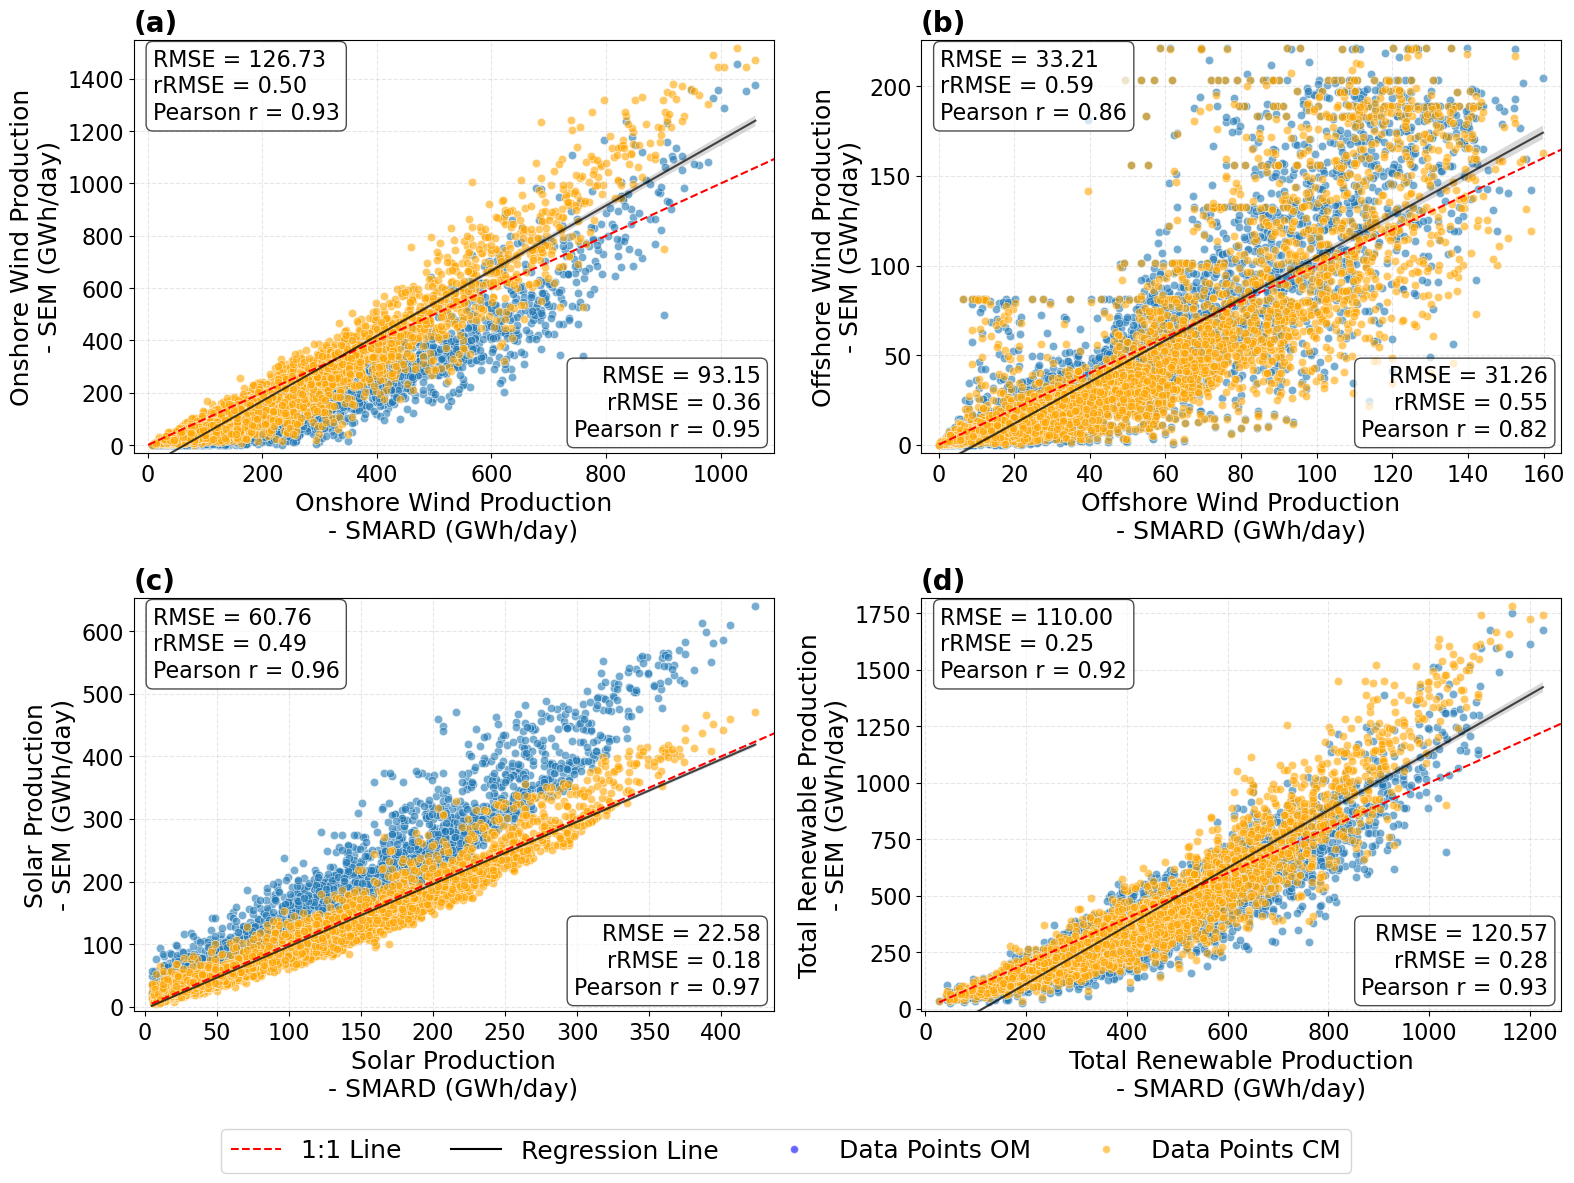

In [17]:
# --- Make all text bigger (global defaults) ---
mpl.rcParams.update({
    'font.size': 14+2,             # base font size (affects legends, labels, etc. unless overridden)
    'axes.titlesize': 18+2,        # axes title
    'axes.labelsize': 16+2,        # x/y labels
    'xtick.labelsize': 14+2,       # x tick labels
    'ytick.labelsize': 14+2,       # y tick labels
    'legend.fontsize': 16+2,       # legend text
    'figure.titlesize': 20+2,      # figure title (if used)
})


rows = [
    "wind_onshore",
    'wind_onshore_OM',
    "wind_offshore",
    "wind_offshore_OM",
    "solar",
    "solar_OM",
    "total_production",
    "total_production_OM"
]
cols = ["whole_year", "winter", 'perc']

# Create empty DataFrame (filled with NaN)
metrics = pd.DataFrame(index=rows, columns=cols)

fig, axs = plt.subplots(2, 2, figsize=(16, 12))
plot_specs = [
    ('wind_onshore_SMARD', 'wind_onshore_ERA5', 'wind_onshore_ERA5_OM', 'Onshore Wind Production'),
    ('wind_offshore_SMARD', 'wind_offshore_ERA5', 'wind_offshore_ERA5_OM', 'Offshore Wind Production'),
    ('solar_SMARD', 'solar_ERA5', 'solar_ERA5_OM', 'Solar Production'),
    ('total_production_SMARD', 'total_production_ERA5', 'total_production_ERA5_OM', 'Total Renewable Production')
]

subplot_labels = ['(a)', '(b)', '(c)', '(d)']

for idx, (ax, (col_smard, col_era5, col_era5_OM, title)) in enumerate(zip(axs.flat, plot_specs)):
    top = col_smard[0:-6]
    top_OM = col_smard[0:-6] + '_OM'

    sns.scatterplot(x=col_smard, y=col_era5_OM, data=df, alpha=0.6, ax=ax)
    
    # 1:1 line
    min_val = min(df[col_smard].min(), df[col_era5].min())
    max_val = max(df[col_smard].max(), df[col_era5].max())
    ax.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--')

    # Adjust axes
    xrange = df[col_smard].max() - df[col_smard].min()
    min_ERA5 = min(df[col_era5].min(), df[col_era5_OM].min())
    max_ERA5 = max(df[col_era5].max(), df[col_era5_OM].max())
    ax.set_xlim(df[col_smard].min() - xrange * 0.03, df[col_smard].max() + xrange * 0.03)
    ax.set_ylim(min_ERA5 - xrange * 0.03, max_ERA5 + xrange * 0.03)

    # Metrics
    r, _ = pearsonr(df[col_smard], df[col_era5])
    rmse = np.sqrt(np.mean((df[col_smard] - df[col_era5])**2))
    metrics.loc[top, 'whole_year'] = rmse
    rmse_OM = np.sqrt(np.mean((df[col_smard] - df[col_era5_OM])**2))
    metrics.loc[top_OM, 'whole_year'] = rmse_OM

    # Corrected points
    if col_era5 == 'wind_onshore_ERA5':
        sns.scatterplot(x=col_smard, y=col_era5, data=df, alpha=0.6, ax=ax, color='orange')
    
    if col_era5 == 'wind_offshore_ERA5':
        sns.scatterplot(x=col_smard, y=col_era5, data=df, alpha=0.6, ax=ax, color='orange')
    
    if col_era5 == 'solar_ERA5':
        sns.scatterplot(x=col_smard, y=col_era5, data=df, alpha=0.6, ax=ax, color='orange')

    if col_era5 == 'total_production_ERA5':
        sns.scatterplot(x=col_smard, y='total_production_ERA5', data=df, alpha=0.6, ax=ax, color='orange')

    # Regression line
    sns.regplot(x=col_smard, y=col_era5, data=df, scatter=False, color='black',
                line_kws={'linewidth': 1.5, 'alpha': 0.7}, ax=ax)
    
    # Plot labels, titles (made larger)
    ax.set_xlabel(f'{title}\n- SMARD (GWh/day)')
    ax.set_ylabel(f'{title}\n- SEM (GWh/day)')
    ax.set_title(subplot_labels[idx], loc='left', fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.3)

    # Metrics
    r, _ = pearsonr(df[col_smard], df[col_era5])
    rmse = np.sqrt(np.mean((df[col_smard] - df[col_era5])**2))
    rrmse = rmse / df[col_smard].mean()
    metrics.loc[top, 'whole_year'] = rmse
    metrics.loc[top, 'rrmse'] = rrmse
    
    r_OM, _ = pearsonr(df[col_smard], df[col_era5_OM])
    rmse_OM = np.sqrt(np.mean((df[col_smard] - df[col_era5_OM])**2))
    rrmse_OM = rmse_OM / df[col_smard].mean()
    metrics.loc[top_OM, 'whole_year'] = rmse_OM
    metrics.loc[top_OM, 'rrmse'] = rrmse_OM

    # Plot labels, titles (made larger)
    ax.set_xlabel(f'{title}\n- SMARD (GWh/day)')
    ax.set_ylabel(f'{title}\n- SEM (GWh/day)')
    ax.set_title(subplot_labels[idx], loc='left', fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.3)

    textstr = '\n'.join((
            f'RMSE = {rmse:.2f}',
            f'rRMSE = {rrmse:.2f}',
            f'Pearson r = {r:.2f}'
        ))

    # if col_era5_OM == 'solar_ERA5_OM' or col_era5_OM == 'total_production_ERA5_OM' or col_era5_OM == 'wind_onshore_ERA5_OM' or col_era5_OM == 'wind_offshore_ERA5_OM':
        # Add numeric-only legend info
    # textstr = '\n'.join((
    #     f'RMSE = {rmse:.2f}',
    #     f'RMSE OM = {rmse_OM:.2f}',
    #     f'Pearson r = {r:.2f}'
    # ))
    # else:
    #     # Add numeric-only legend info
    #     textstr = '\n'.join((
    #         f'RMSE = {rmse:.2f}',
    #         f'Pearson r = {r:.2f}'
    #     ))
    
    ax.text(0.98, 0.03, textstr, transform=ax.transAxes,
            va='bottom', ha='right',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))

    textstr_OM = '\n'.join((
            f'RMSE = {rmse_OM:.2f}',
            f'rRMSE = {rrmse_OM:.2f}',
            f'Pearson r = {r_OM:.2f}'
        ))
    
    ax.text(0.03, 0.98, textstr_OM, transform=ax.transAxes,
            va='top', ha='left',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))

# Create a common legend
legend_elements = [
    Line2D([0], [0], linestyle='--', color='red', label='1:1 Line'),
    Line2D([0], [0], linestyle='-', color='black', label='Regression Line'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='blue', label='Data Points OM', alpha=0.6),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='orange', label='Data Points CM', alpha=0.6),
]

# Place common legend below all subplots (fontsize increased slightly)
fig.legend(handles=legend_elements, loc='lower center', ncol=4, frameon=True, bbox_to_anchor=(0.5, 0))

plt.tight_layout(rect=[0, 0.05, 1, 1])  # leave space for legend

# Save the figure
# plt.savefig('/home/onennecke/Code/Figures/Mod_eval_scatterplt_with_OM.png', dpi=300, bbox_inches='tight')
plt.show()


#### Only winter data

In [18]:
df_win = df[df['date'].dt.month.isin([1, 2, 3, 10, 11, 12])]
df_win

,date,demand_SMARD,wind_offshore_SMARD,wind_onshore_SMARD,solar_SMARD,total_production_SMARD,residual_load_SMARD,sfcWind,rsds,tas,...,total_production_ERA5,total_production_ERA5_check,weekday,period,special,wind_offshore_ERA5_OM,wind_onshore_ERA5_OM,solar_ERA5_OM,total_production_ERA5_OM,total_production_ERA5_OM_check
0,2015-01-01,1096.85275,12.50850,298.79175,17.08025,328.38050,768.47225,7.506850,30.539927,1.771455,...,491.201038,491.201038,4,Weekday,holiday,81.165600,273.221636,32.737423,387.124659,387.124659
1,2015-01-02,1288.91475,10.32925,591.62075,7.75900,609.70900,679.20575,11.862523,19.505219,3.586776,...,888.751712,888.751712,5,Weekday,Weekday,81.165600,674.062933,17.379115,772.607648,772.607648
2,2015-01-03,1213.30950,12.11950,457.04350,7.23475,476.39775,736.91175,9.267174,17.846884,3.046391,...,651.048379,651.048379,6,Weekend,Weekend,81.165600,430.882580,16.647296,528.695476,528.695476
3,2015-01-04,1177.89600,11.53850,379.02950,19.98250,410.55050,767.34550,8.975194,35.401741,2.561011,...,540.436987,540.436987,7,Weekend,Weekend,76.352622,309.093051,34.760317,420.205991,420.205991
4,2015-01-05,1425.92750,7.74550,219.62350,26.52225,253.89125,1172.03625,6.101583,29.677082,1.703392,...,220.810651,220.810651,1,Weekday,Weekday,21.225734,109.377943,34.330604,164.934282,164.934282
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3648,2024-12-27,1155.15125,2.94125,46.42200,61.20575,110.56900,1044.58225,2.513451,32.226482,1.191884,...,86.696898,86.696898,5,Weekday,christmas,3.365156,3.016724,89.412064,95.793945,95.793945
3649,2024-12-28,1150.65975,22.34775,31.44225,61.08850,114.87850,1035.78125,3.093119,34.692463,-0.210155,...,117.648017,117.648017,6,Weekend,christmas,16.483505,7.948019,96.813305,121.244829,121.244829
3650,2024-12-29,1179.16200,97.29825,257.39450,39.71900,394.41175,784.75025,6.158602,28.835943,0.223771,...,543.309610,543.309610,7,Weekend,christmas,179.232693,216.614284,78.486247,474.333224,474.333224
3651,2024-12-30,1278.28500,61.18675,534.34725,22.92750,618.46150,659.82350,8.049464,26.303263,1.511976,...,1053.671601,1053.671601,1,Weekday,christmas,221.142798,592.833808,72.300292,886.276898,886.276898


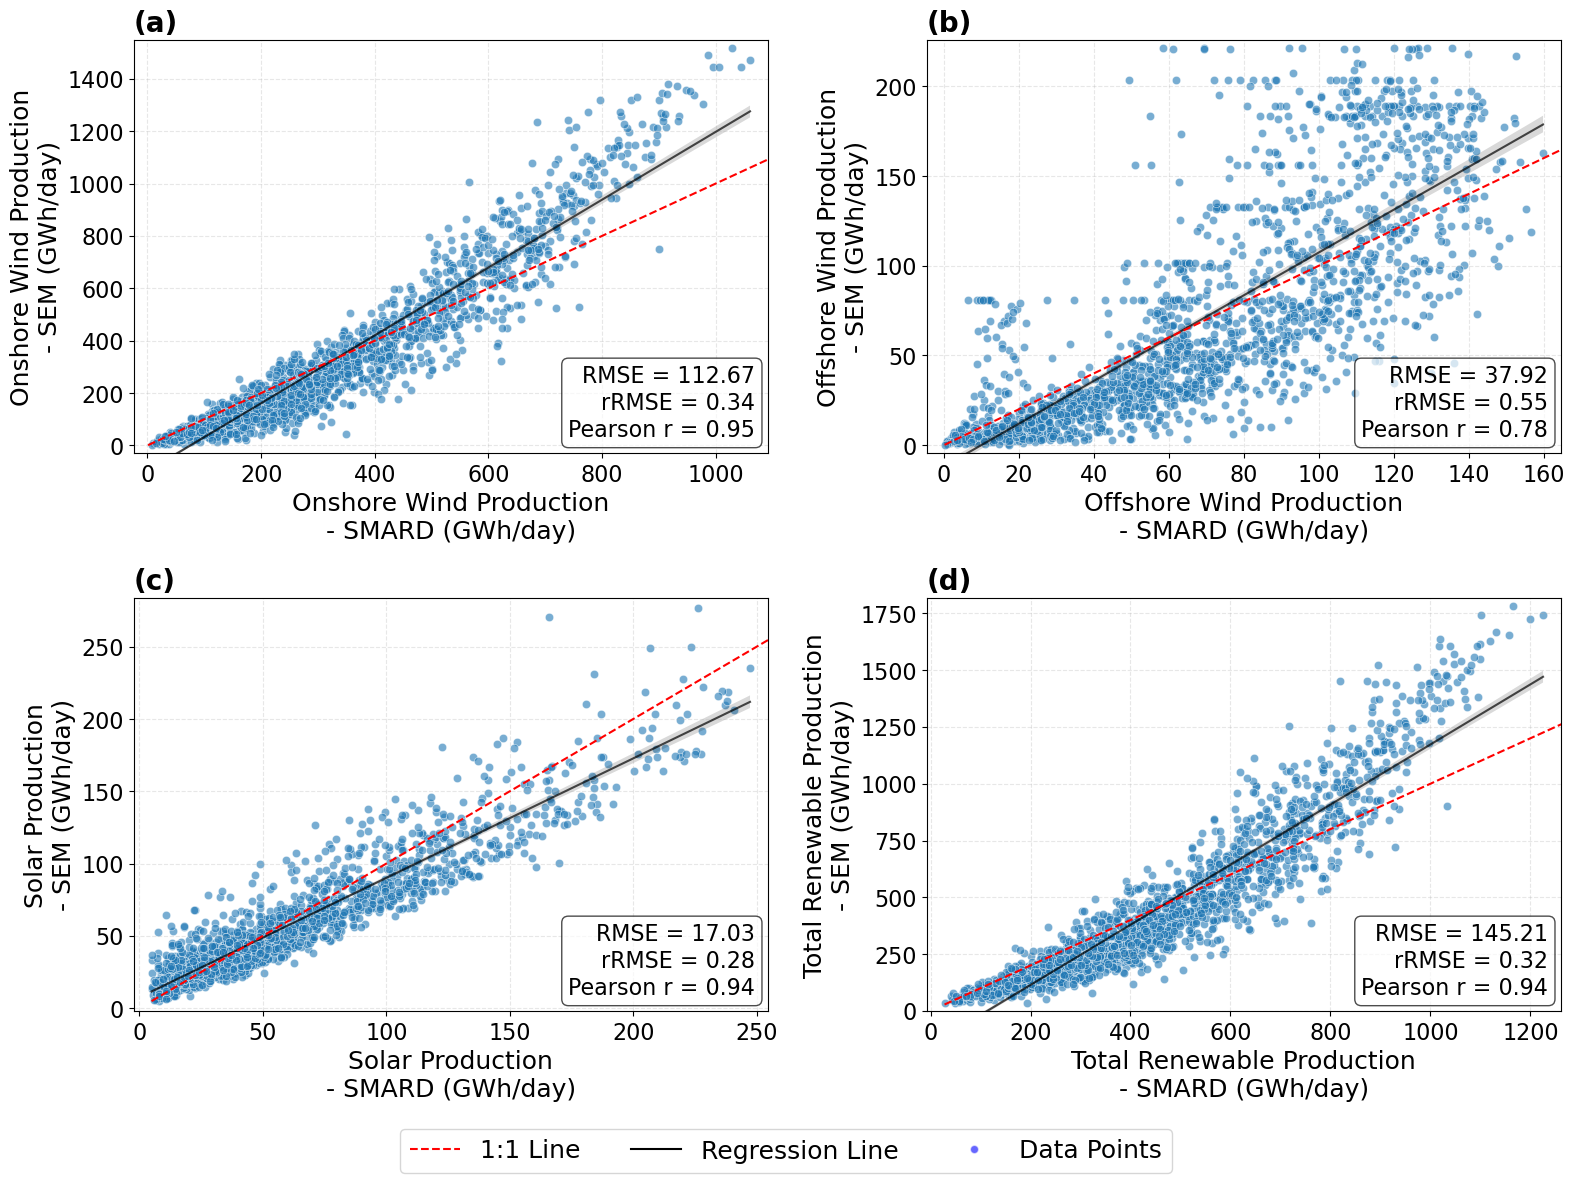

In [19]:
plot_all(df_win, setlim=False)

In [20]:
rows = ['wind_onshore', 'wind_offshore', 'solar', 'total_production']
cols = ["whole_year", "winter", 'perc']

metrics = pd.DataFrame(index=rows, columns=cols)

for col_smard, col_era5 in zip(['wind_onshore_SMARD', 'wind_offshore_SMARD', 'solar_SMARD', 'total_production_SMARD'],
                            ['wind_onshore_ERA5', 'wind_offshore_ERA5', 'solar_ERA5', 'total_production_ERA5']):
    top = col_smard[0:-6]
    # Metrics
    r, _ = pearsonr(df[col_smard], df[col_era5])
    rmse = np.sqrt(np.mean((df[col_smard] - df[col_era5])**2))
    metrics.loc[top, 'whole_year'] = rmse
    
    r, _ = pearsonr(df_win[col_smard], df_win[col_era5])
    rmse = np.sqrt(np.mean((df_win[col_smard] - df_win[col_era5])**2))
    metrics.loc[top, 'winter'] = rmse

# Calculate how much worse/better the winter data is compared to the full dataset in percent in the third column of the `metrics` DataFrame
metrics['perc'] = (metrics['winter'] - metrics['whole_year']) / metrics['whole_year'] * 100
metrics

,whole_year,winter,perc
wind_onshore,93.147912,112.666631,20.954543
wind_offshore,31.258464,37.915113,21.295508
solar,22.576591,17.026068,-24.585304
total_production,120.568168,145.211062,20.438972


In [24]:
# Filter only the 10 % highest values of the residual load
df_highest_residual = df[df['RL_ERA5'] > df['RL_ERA5'].quantile(0.9)]
df_lowest_prod = df[df['total_production_ERA5'] < df['total_production_ERA5'].quantile(0.1)]
df_highest_demand = df[df['demand_ERA5'] > df['demand_ERA5'].quantile(0.9)]

In [25]:
print(df['RL_ERA5'].quantile(0.95))
df_LEE = df[df['RL_ERA5'] > df['RL_ERA5'].quantile(0.95)]

1367.911456066887


In [27]:
metrics['high_rl'] = np.nan
metrics

for col_smard, col_era5 in zip(['wind_onshore_SMARD', 'wind_offshore_SMARD', 'solar_SMARD', 'total_production_SMARD'],
                            ['wind_onshore_ERA5', 'wind_offshore_ERA5', 'solar_ERA5', 'total_production_ERA5']):
    top = col_smard[0:-6]
    # Metrics
    r, _ = pearsonr(df_LEE[col_smard], df_LEE[col_era5])
    rmse = np.sqrt(np.mean((df_LEE[col_smard] - df_LEE[col_era5])**2))
    metrics.loc[top, 'high_rl'] = rmse
metrics['perc_rl'] = (metrics['high_rl'] - metrics['whole_year']) / metrics['whole_year'] * 100
metrics

,whole_year,winter,perc,high_rl,perc_rl
wind_onshore,93.147912,112.666631,20.954543,51.182333,-45.052624
wind_offshore,31.258464,37.915113,21.295508,19.306411,-38.236214
solar,22.576591,17.026068,-24.585304,14.226827,-36.984168
total_production,120.568168,145.211062,20.438972,63.692254,-47.173242


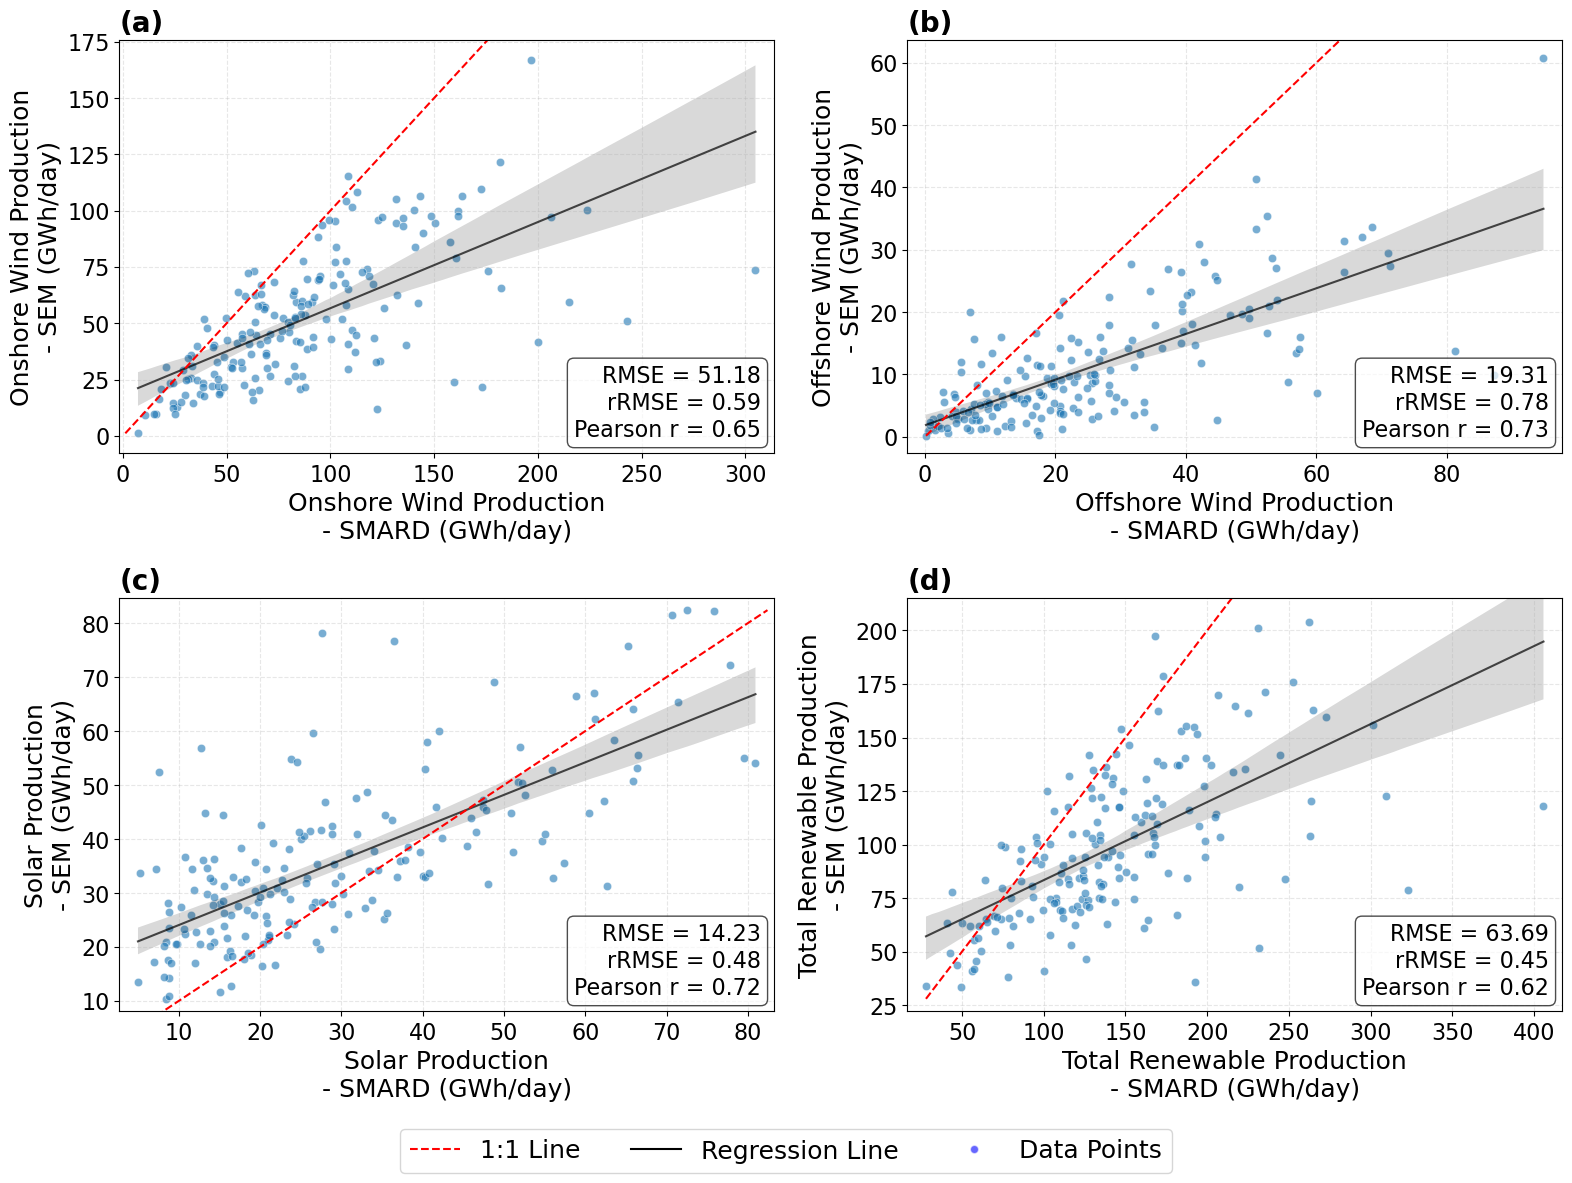

In [28]:
plot_all(df_LEE, setlim=False)

### Demand

In [29]:
df_demand = df.drop(columns=['wind_offshore_SMARD', 'wind_onshore_SMARD', 'solar_SMARD', 'total_production_SMARD',
                             'wind_onshore_ERA5', 'wind_offshore_ERA5', 'solar_ERA5', 'total_production_ERA5'])
df_demand['dem_SMARD_RM'] = df_demand['demand_SMARD'].rolling(window=7, min_periods=1).mean()
df_demand['dem_ERA5_RM'] = df_demand['demand_ERA5'].rolling(window=7, min_periods=1).mean()
df_demand['dem_ERA5_wwd_RM'] = df_demand['demand_ERA5_wwd'].rolling(window=7, min_periods=1).mean()
df_demand

,date,demand_SMARD,residual_load_SMARD,sfcWind,rsds,tas,tasmax,temp_ERA5,demand_ERA5_wwd,demand_ERA5,...,period,special,wind_offshore_ERA5_OM,wind_onshore_ERA5_OM,solar_ERA5_OM,total_production_ERA5_OM,total_production_ERA5_OM_check,dem_SMARD_RM,dem_ERA5_RM,dem_ERA5_wwd_RM
0,2015-01-01,1096.85275,768.47225,7.506850,30.539927,1.771455,3.431339,1.323001,1581.917233,1503.583224,...,Weekday,holiday,81.165600,273.221636,32.737423,387.124659,387.124659,1096.852750,1503.583224,1581.917233
1,2015-01-02,1288.91475,679.20575,11.862523,19.505219,3.586776,5.871274,3.334620,1556.334218,1478.646694,...,Weekday,Weekday,81.165600,674.062933,17.379115,772.607648,772.607648,1192.883750,1491.114959,1569.125726
2,2015-01-03,1213.30950,736.91175,9.267174,17.846884,3.046391,4.704414,2.591276,1291.701049,1487.881204,...,Weekend,Weekend,81.165600,430.882580,16.647296,528.695476,528.695476,1199.692333,1490.037041,1476.650833
3,2015-01-04,1177.89600,767.34550,8.975194,35.401741,2.561011,4.239970,2.345489,1294.625490,1490.928814,...,Weekend,Weekend,76.352622,309.093051,34.760317,420.205991,420.205991,1194.243250,1490.259984,1431.144497
4,2015-01-05,1425.92750,1172.03625,6.101583,29.677082,1.703392,3.319645,1.338708,1581.718548,1503.389075,...,Weekday,Weekday,21.225734,109.377943,34.330604,164.934282,164.934282,1240.580100,1492.885802,1461.259308
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3648,2024-12-27,1155.15125,1044.58225,2.513451,32.226482,1.191884,3.729366,0.706743,1589.701965,1511.195532,...,Weekday,christmas,3.365156,3.016724,89.412064,95.793945,95.793945,1168.716750,1481.356119,1481.263696
3649,2024-12-28,1150.65975,1035.78125,3.093119,34.692463,-0.210155,2.485461,-0.852848,1332.645250,1530.428151,...,Weekend,christmas,16.483505,7.948019,96.813305,121.244829,121.244829,1151.682214,1491.388453,1490.893771
3650,2024-12-29,1179.16200,784.75025,6.158602,28.835943,0.223771,2.445564,-0.673827,1330.517982,1528.222259,...,Weekend,christmas,179.232693,216.614284,78.486247,474.333224,474.333224,1150.412393,1499.919366,1499.088455
3651,2024-12-30,1278.28500,659.82350,8.049464,26.303263,1.511976,2.708793,0.739563,1589.287859,1510.790344,...,Weekday,christmas,221.142798,592.833808,72.300292,886.276898,886.276898,1150.707071,1503.625650,1502.885688


/tmp/ipykernel_128937/3520207648.py:18: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(x='dem_SMARD_RM', y='dem_ERA5_RM', data=df_demand, alpha=0.6, palette='Set2', ax=ax, label='7-day Rolling Mean')


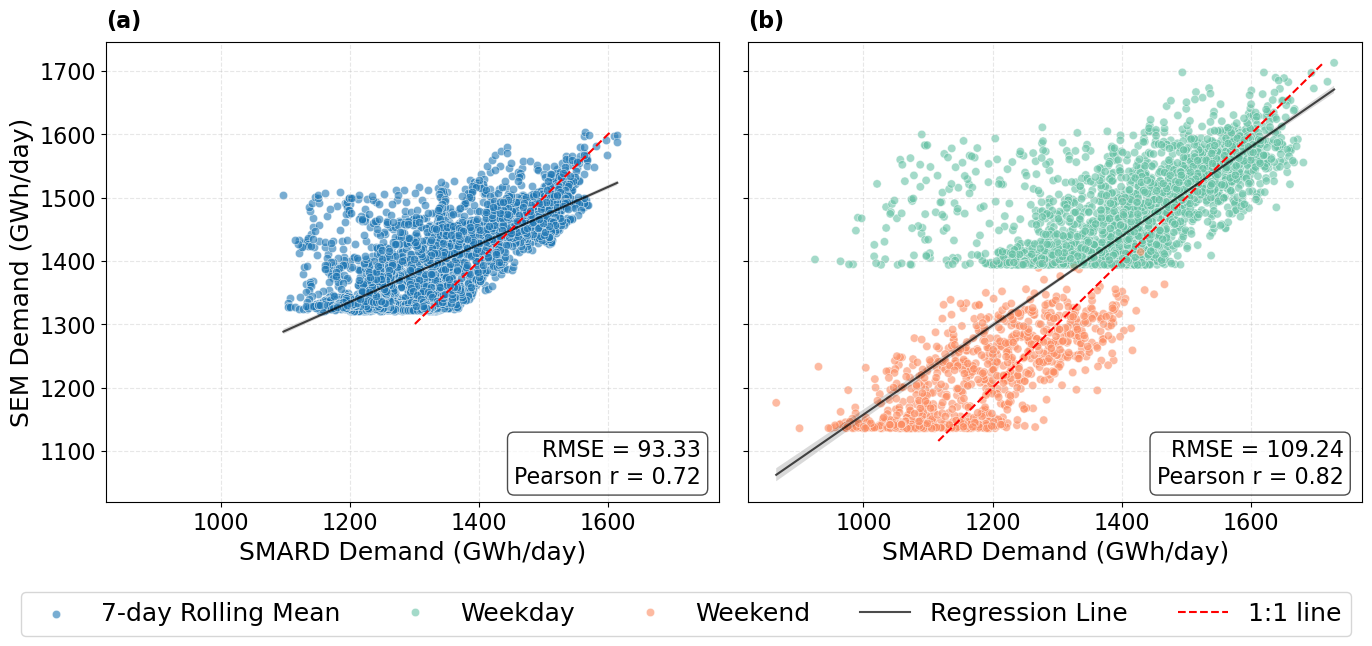

In [30]:
# --- Make all text bigger (global defaults) ---
mpl.rcParams.update({
    'font.size': 14+2,         # base font size
    'axes.labelsize': 16+2,    # x/y labels
    'axes.titlesize': 18+2,    # axes titles (if used)
    'xtick.labelsize': 14+2,   # x tick labels
    'ytick.labelsize': 14+2,   # y tick labels
    'legend.fontsize': 16+2,   # legend text
    'figure.titlesize': 20+2,  # figure title (if used)
})

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

# -------------------------
# Subplot (a)
# -------------------------
ax = axes[0]
sns.scatterplot(x='dem_SMARD_RM', y='dem_ERA5_RM', data=df_demand, alpha=0.6, palette='Set2', ax=ax, label='7-day Rolling Mean')

# Regression line
sns.regplot(x='dem_SMARD_RM', y='dem_ERA5_RM', data=df_demand, scatter=False, 
            color='black', line_kws={'linewidth': 1.5, 'alpha': 0.7}, ax=ax)

# Metrics: Pearson correlation + RMSE (drop NaNs for safe calc)
sub = df_demand[['dem_SMARD_RM', 'dem_ERA5_RM']].dropna()
r, _ = pearsonr(sub['dem_SMARD_RM'], sub['dem_ERA5_RM'])
rmse = np.sqrt(np.mean((sub['dem_SMARD_RM'] - sub['dem_ERA5_RM'])**2))

# Put both metrics into a boxed text at lower right (larger font)
textstr = '\n'.join((
    f'RMSE = {rmse:.2f}',
    f'Pearson r = {r:.2f}'
))
ax.text(0.97, 0.03, textstr, transform=ax.transAxes,
        va='bottom', ha='right',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))

# 1:1 line
x = np.linspace(df_demand['dem_ERA5_RM'].min()-20, df_demand['dem_ERA5_RM'].max(), 100)
ax.plot(x, x, color='red', linestyle='--')

# Bigger axis labels (only size changed)
ax.set_xlabel('SMARD Demand (GWh/day)')
ax.set_ylabel('SEM Demand (GWh/day)')

ax.grid(True, linestyle='--', alpha=0.3)
# remove individual legend to avoid duplicates in combined legend (safe removal)
if getattr(ax, "legend_", None):
    ax.legend_.remove()

# Panel label (made larger)
ax.text(0, 1.07, '(a)', transform=ax.transAxes, fontweight='bold', va='top')

# -------------------------
# Subplot (b)
# -------------------------
ax = axes[1]
sns.scatterplot(x='demand_SMARD', y='demand_ERA5_wwd', hue='period', data=df_demand, 
                alpha=0.6, palette='Set2', ax=ax)

# Regression line
sns.regplot(x='demand_SMARD', y='demand_ERA5_wwd', data=df_demand, scatter=False, 
            color='black', line_kws={'linewidth': 1.5, 'alpha': 0.7}, ax=ax, label='Regression Line')

# Metrics: Pearson correlation + RMSE (drop NaNs for safe calc)
sub = df_demand[['demand_SMARD', 'demand_ERA5_wwd']].dropna()
r, _ = pearsonr(sub['demand_SMARD'], sub['demand_ERA5_wwd'])
rmse = np.sqrt(np.mean((sub['demand_SMARD'] - sub['demand_ERA5_wwd'])**2))

# Put both metrics into a boxed text at lower right (larger font)
textstr = '\n'.join((
    f'RMSE = {rmse:.2f}',
    f'Pearson r = {r:.2f}'
))
ax.text(0.97, 0.03, textstr, transform=ax.transAxes,
        va='bottom', ha='right',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))

# 1:1 line
x = np.linspace(df_demand['demand_ERA5_wwd'].min()-20, df_demand['demand_ERA5_wwd'].max(), 100)
ax.plot(x, x, color='red', linestyle='--', label='1:1 line')

# Bigger axis labels
ax.set_xlabel('SMARD Demand (GWh/day)')
ax.set_ylabel('SEM Demand (GWh/day)')

ax.grid(True, linestyle='--', alpha=0.3)
# remove individual legend to avoid duplicates in combined legend (safe removal)
if getattr(ax, "legend_", None):
    ax.legend_.remove()

# --- remove per-axis legends above ---
# Create shared legend underneath both subplots
handles1, labels1 = axes[0].get_legend_handles_labels()
handles2, labels2 = axes[1].get_legend_handles_labels()

# combine while preserving order and skipping empty labels
seen = set()
combined = []
for h, l in zip(handles1 + handles2, labels1 + labels2):
    if l and l not in seen:
        seen.add(l)
        combined.append((h, l))

if combined:
    handles, labels = zip(*combined)
    plt.subplots_adjust(bottom=0.18)                      # make room at bottom
    # make shared legend text larger
    fig.legend(handles, labels, loc='lower center', ncol=len(labels), bbox_to_anchor=(0.5, -0.1))

# Panel label (b) (made larger)
ax.text(0, 1.07, '(b)', transform=ax.transAxes, fontweight='bold', va='top')

plt.tight_layout()
# Save the figure
# plt.savefig('/home/onennecke/Code/Figures/demand_correlation_combined.png', dpi=300, bbox_inches='tight')

plt.show()

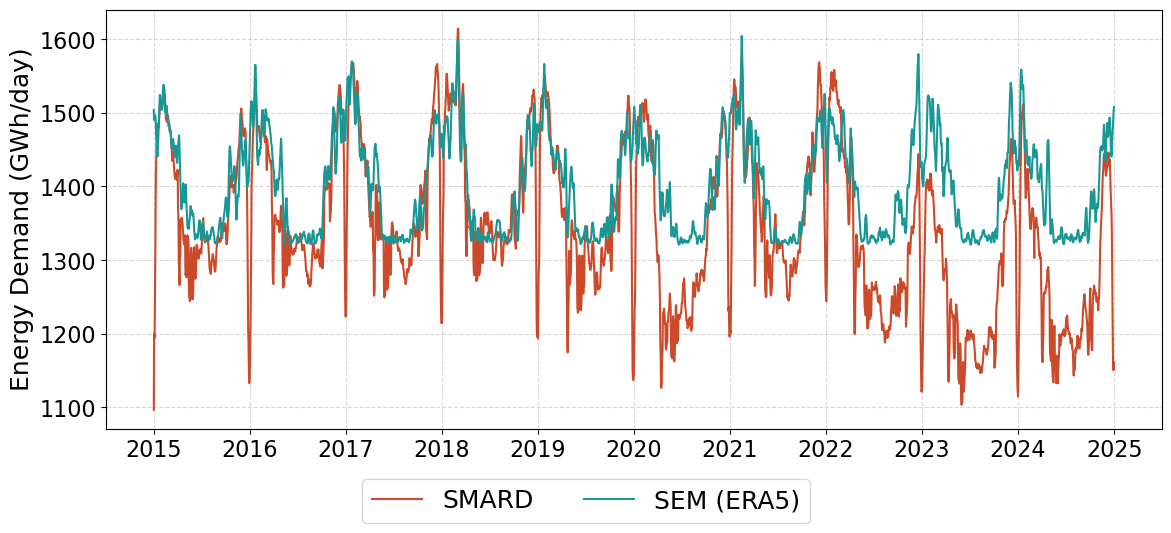

In [37]:
# --- Make all text bigger (global defaults) ---
mpl.rcParams.update({
    'font.size': 14+2,          # base font size
    'axes.titlesize': 18+2,     # title
    'axes.labelsize': 16+2,     # axis labels
    'xtick.labelsize': 14+2,    # x tick labels
    'ytick.labelsize': 14+2,    # y tick labels
    'legend.fontsize': 16+2,    # legend text (fallback)
    'figure.titlesize': 20+2,   # figure title (if used elsewhere)
})

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df_demand['date'], df_demand['dem_SMARD_RM'], label='SMARD', color="#CC4A2A")
ax.plot(df_demand['date'], df_demand['dem_ERA5_RM'], label='SEM (ERA5)', color="#189797")

# title and ylabel (explicit sizes to be safe)
# ax.set_title('SMARD vs SEM (ERA5) Demand', fontsize=18)
ax.set_ylabel('Energy Demand (GWh/day)')

ax.grid(True, linestyle='--', alpha=0.5)

# collect handles & labels and create a centered legend below the axes
handles, labels = ax.get_legend_handles_labels()
if handles:
    # make room at bottom for the legend
    fig.subplots_adjust(bottom=0.18)
    fig.legend(handles, labels, loc='lower center',
               ncol=len(labels), bbox_to_anchor=(0.5, -0.1),
               frameon=True)

plt.tight_layout()
# save the figure
# plt.savefig('/home/onennecke/Code/Figures/demand_time_series_RM.png', dpi=300, bbox_inches='tight')
plt.show()


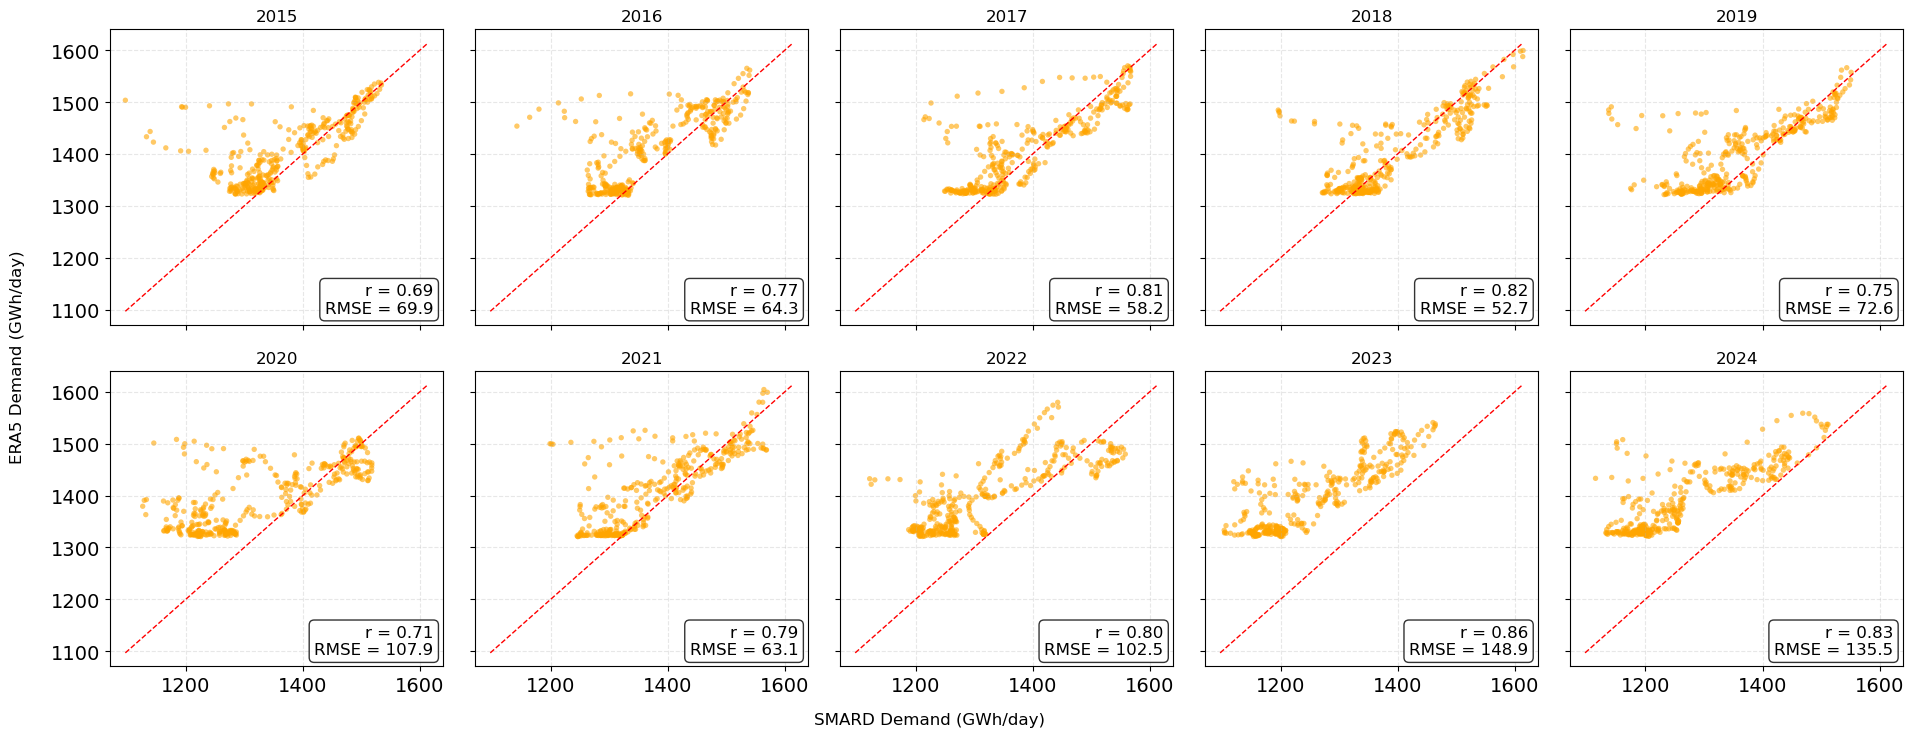

In [43]:

# 1) Prepare your DataFrame
df_demand['date'] = pd.to_datetime(df_demand['date'])
df_demand.set_index('date', inplace=True)
df_demand['year'] = df_demand.index.year

# 2) Set up 2×5 subplots for 2015–2024
years = list(range(2015, 2025))
fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharex=True, sharey=True)
axes = axes.flatten()

min_val = min(df_demand['dem_ERA5_RM'].min(), df_demand['dem_SMARD_RM'].min())
max_val = max(df_demand['dem_ERA5_RM'].max(), df_demand['dem_SMARD_RM'].max())

for ax, year in zip(axes, years):
    # Filter for this year
    data_year = df_demand[df_demand['year'] == year]
    x = data_year['dem_SMARD_RM'].dropna()
    y = data_year['dem_ERA5_RM'].dropna()

    # Scatter
    ax.scatter(x, y, alpha=0.6, s=15, color='orange', edgecolor='none')
    
    # 1:1 line
    # lo = min(ax.get_xlim()[0], ax.get_ylim()[0])
    # hi = max(ax.get_xlim()[1], ax.get_ylim()[1])
    # ax.plot([lo, hi], [lo, hi], 'r--', lw=1)
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=1)

    
    # Compute & annotate Pearson r and RMSE
    if len(x) > 1:
        r, _ = pearsonr(x, y)
        rmse = np.sqrt(np.mean((x - y)**2))
        ax.text(
            0.97, 0.03,
            f"r = {r:.2f}\nRMSE = {rmse:.1f}",
            transform=ax.transAxes,
            ha='right', va='bottom',
            fontsize=12,
            bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.3')
        )

    ax.set_title(str(year), fontsize=12)
    ax.grid(True, linestyle='--', alpha=0.3)

# Global axis labels
fig.text(0.5, 0.04, 'SMARD Demand (GWh/day)', ha='center', fontsize=12)
fig.text(0.04, 0.5, 'ERA5 Demand (GWh/day)', va='center', rotation='vertical', fontsize=12)

# plt.suptitle('Per-Year SMARD vs ERA5 Demand (2015–2024)', fontsize=16, y=0.98)
plt.tight_layout(rect=[0.05, 0.05, 1, 0.96])
# Save the figure
# plt.savefig('/home/onennecke/Code/Figures/demand_per_year_scatter_draft.png', dpi=300, bbox_inches='tight')
plt.show()


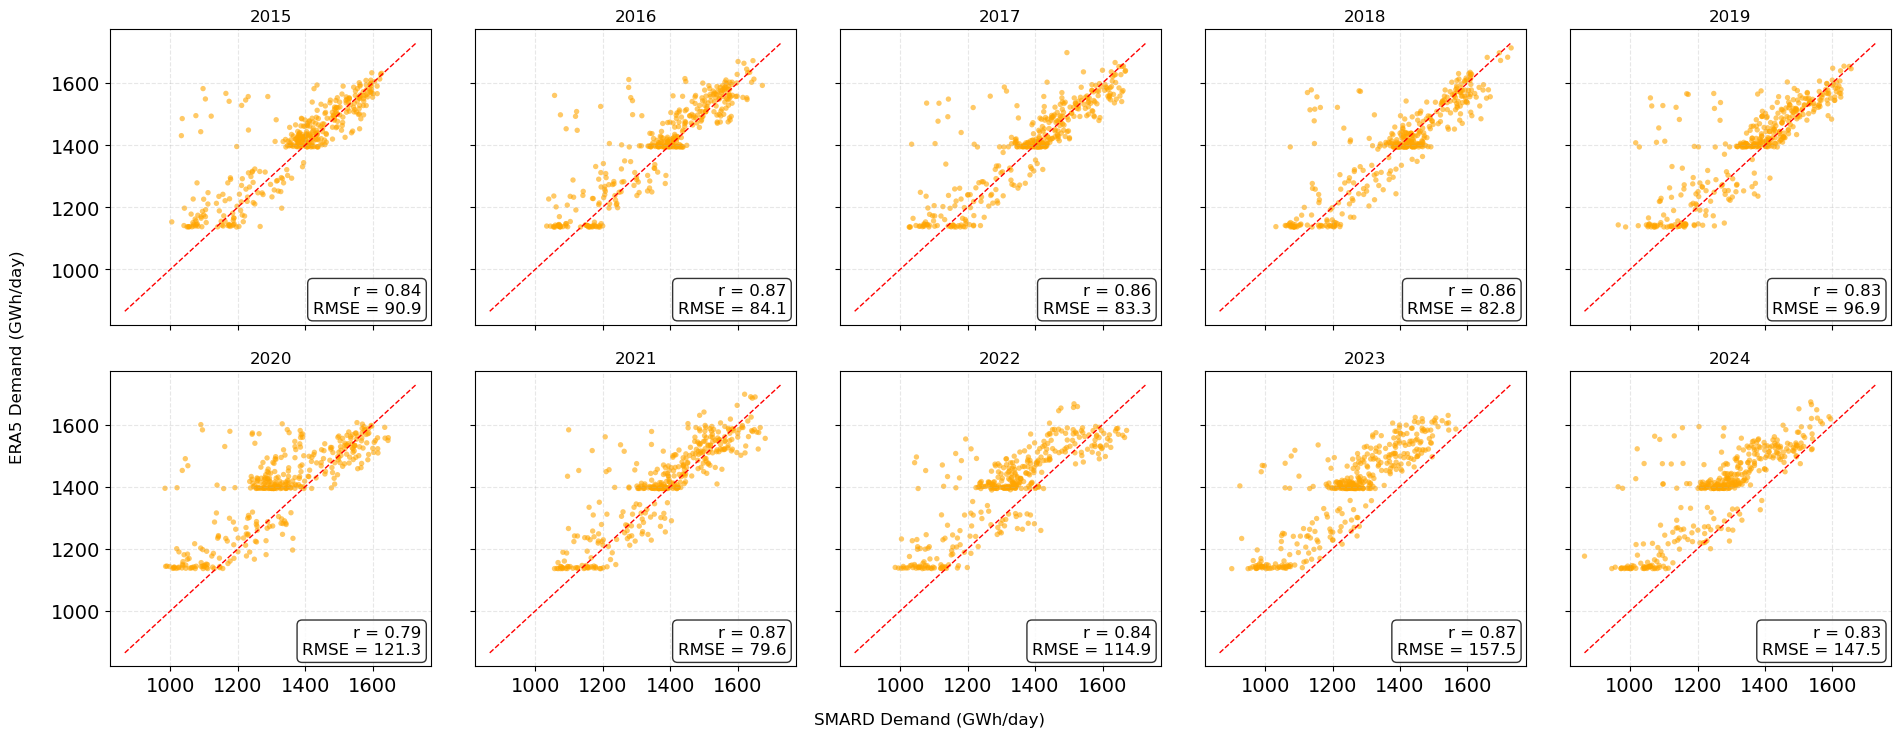

In [44]:

df_demand = df.copy()
# 1) Prepare your DataFrame
df_demand['date'] = pd.to_datetime(df_demand['date'])
df_demand.set_index('date', inplace=True)
df_demand['year'] = df_demand.index.year

# 2) Set up 2×5 subplots for 2015–2024
years = list(range(2015, 2025))
fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharex=True, sharey=True)
axes = axes.flatten()

min_val = min(df_demand['demand_ERA5_wwd'].min(), df_demand['demand_SMARD'].min())
max_val = max(df_demand['demand_ERA5_wwd'].max(), df_demand['demand_SMARD'].max())

for ax, year in zip(axes, years):
    # Filter for this year
    data_year = df_demand[df_demand['year'] == year]
    x = data_year['demand_SMARD'].dropna()
    y = data_year['demand_ERA5_wwd'].dropna()
    
    # Scatter
    ax.scatter(x, y, alpha=0.6, s=15, color='orange', edgecolor='none')
    
    # 1:1 line
    # lo = min(ax.get_xlim()[0], ax.get_ylim()[0])
    # hi = max(ax.get_xlim()[1], ax.get_ylim()[1])
    # ax.plot([lo, hi], [lo, hi], 'r--', lw=1)
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=1)

    
    # Compute & annotate Pearson r and RMSE
    if len(x) > 1:
        r, _ = pearsonr(x, y)
        rmse = np.sqrt(np.mean((x - y)**2))
        ax.text(
            0.97, 0.03,
            f"r = {r:.2f}\nRMSE = {rmse:.1f}",
            transform=ax.transAxes,
            ha='right', va='bottom',
            fontsize=12,
            bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.3')
        )

    ax.set_title(str(year), fontsize=12)
    ax.grid(True, linestyle='--', alpha=0.3)

# Global axis labels
fig.text(0.5, 0.04, 'SMARD Demand (GWh/day)', ha='center', fontsize=12)
fig.text(0.04, 0.5, 'ERA5 Demand (GWh/day)', va='center', rotation='vertical', fontsize=12)

# plt.suptitle('Per-Year SMARD vs ERA5 Demand (2015–2024)', fontsize=16, y=0.98)
plt.tight_layout(rect=[0.05, 0.05, 1, 0.96])
# Save the figure
# plt.savefig('/home/onennecke/Code/Figures/demand_per_year_scatter_draft.png', dpi=300, bbox_inches='tight')
plt.show()


### Model visualisation plot

In [45]:

demand_fit_values = xr.open_dataset('/climca/people/onennecke/population_data/demand_fit_values_week.nc')
# Create array from -15:45
temperature_plt = np.arange(-20, 60.5, 0.5)
v_weekday = demand_fit_values.sel(country = 9, period = 'weekday')
v_weekend = demand_fit_values.sel(country = 9, period = 'weekend')
v_week = demand_fit_values.sel(country = 9, period = 'week')

demand_weekday = np.zeros(len(temperature_plt))
demand_weekend = np.zeros(len(temperature_plt))
demand_week = np.zeros(len(temperature_plt))

for i in range(len(temperature_plt)):
    demand_weekday[i] = demand.LSTRmodel(temperature_plt[i], v_weekday)
    if (demand_weekday[i] > v_weekday.heating_max) & (temperature_plt[i] < v_weekday.f):
        demand_weekday[i] = v_weekday.heating_max
    if (demand_weekday[i] > v_weekday.cooling_max) & (temperature_plt[i] > v_weekday.f):
        demand_weekday[i] = v_weekday.cooling_max

    demand_weekend[i] = demand.LSTRmodel(temperature_plt[i], v_weekend)
    if (demand_weekend[i] > v_weekend.heating_max) & (temperature_plt[i] < v_weekend.f):
        demand_weekend[i] = v_weekend.heating_max
    if (demand_weekend[i] > v_weekend.cooling_max) & (temperature_plt[i] > v_weekend.f):
        demand_weekend[i] = v_weekend.cooling_max
    
    demand_week[i] = demand.LSTRmodel(temperature_plt[i], v_week)
    if (demand_week[i] > v_week.heating_max) & (temperature_plt[i] < v_week.f):
        demand_week[i] = v_week.heating_max
    if (demand_week[i] > v_week.cooling_max) & (temperature_plt[i] > v_week.f):
        demand_week[i] = v_week.cooling_max

In [46]:
print(v_week.heating_max.values.round(2), v_week.cooling_max.values.round(2))
v_week.cooling_max.values

1702.51 1472.8


array(1472.80486656)

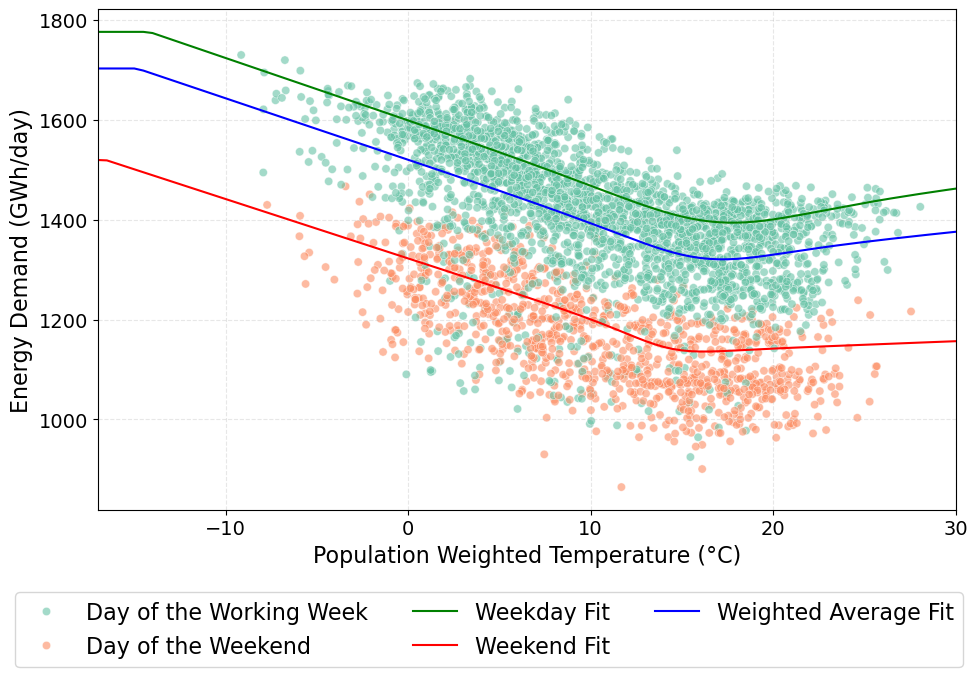

In [47]:
# --- Make all text bigger (global defaults) ---
mpl.rcParams.update({
    'font.size': 14,          # base font size
    'axes.titlesize': 18,     # title
    'axes.labelsize': 16,     # axis labels
    'xtick.labelsize': 14,    # x tick labels
    'ytick.labelsize': 14,    # y tick labels
    'legend.fontsize': 16,    # legend text (fallback)
    'figure.titlesize': 20,   # figure title (if used)
})

fig, ax = plt.subplots(figsize=(10, 6))

# Scatterplot (uses the axes object now)
scatter = sns.scatterplot(x='temp_ERA5', y='demand_SMARD', hue='period', data=df, alpha=0.6, palette='Set2', ax=ax)

# Line plots (capture the Line2D objects)
line1 = ax.plot(temperature_plt, demand_weekday, linestyle='-', color='g', label='Weekday Fit')
line2 = ax.plot(temperature_plt, demand_weekend, linestyle='-', color='r', label='Weekend Fit')
line3 = ax.plot(temperature_plt, demand_week, linestyle='-', color='b', label='Weighted Average Fit')

# Remove the automatic in-axes legend created by seaborn
if getattr(ax, "legend_", None):
    ax.legend_.remove()

# Get handles and labels from scatter (hue categories)
scatter_handles, scatter_labels = scatter.get_legend_handles_labels()
# rename the first two scatter labels just like in your original snippet
if len(scatter_labels) >= 2:
    scatter_labels[0], scatter_labels[1] = 'Day of the Working Week', 'Day of the Weekend'

# line handles (each plot returns a list; take the first element)
line_handles = [line1[0], line2[0], line3[0]]
line_labels  = ['Weekday Fit', 'Weekend Fit', 'Weighted Average Fit']

# Combine handles/labels: scatter first, then lines
handles = scatter_handles + line_handles
labels  = scatter_labels + line_labels

# Deduplicate so each label appears only once (preserve order)
unique_handles = []
unique_labels = []
seen = set()
for h, l in zip(handles, labels):
    if l and l not in seen:
        seen.add(l)
        unique_handles.append(h)
        unique_labels.append(l)

# Make room at bottom and put a centered legend underneath
if unique_handles:
    fig.subplots_adjust(bottom=0.18)  # create space for the legend
    fig.legend(unique_handles, unique_labels, loc='lower center',
               ncol=3, bbox_to_anchor=(0.5, -0.15),
               fontsize=16, frameon=True)

# Axes labels (explicit sizes to be safe)
ax.set_ylabel('Energy Demand (GWh/day)', fontsize=16)
ax.set_xlabel('Population Weighted Temperature (°C)', fontsize=16)

ax.set_xlim([-10, 30])
ax.set_xlim([-17, 30])

ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()

# save the plot
# plt.savefig('/home/onennecke/Code/Figures/demand_fit_germany.png', dpi=300, bbox_inches='tight')

plt.show()


### Compare variables to output

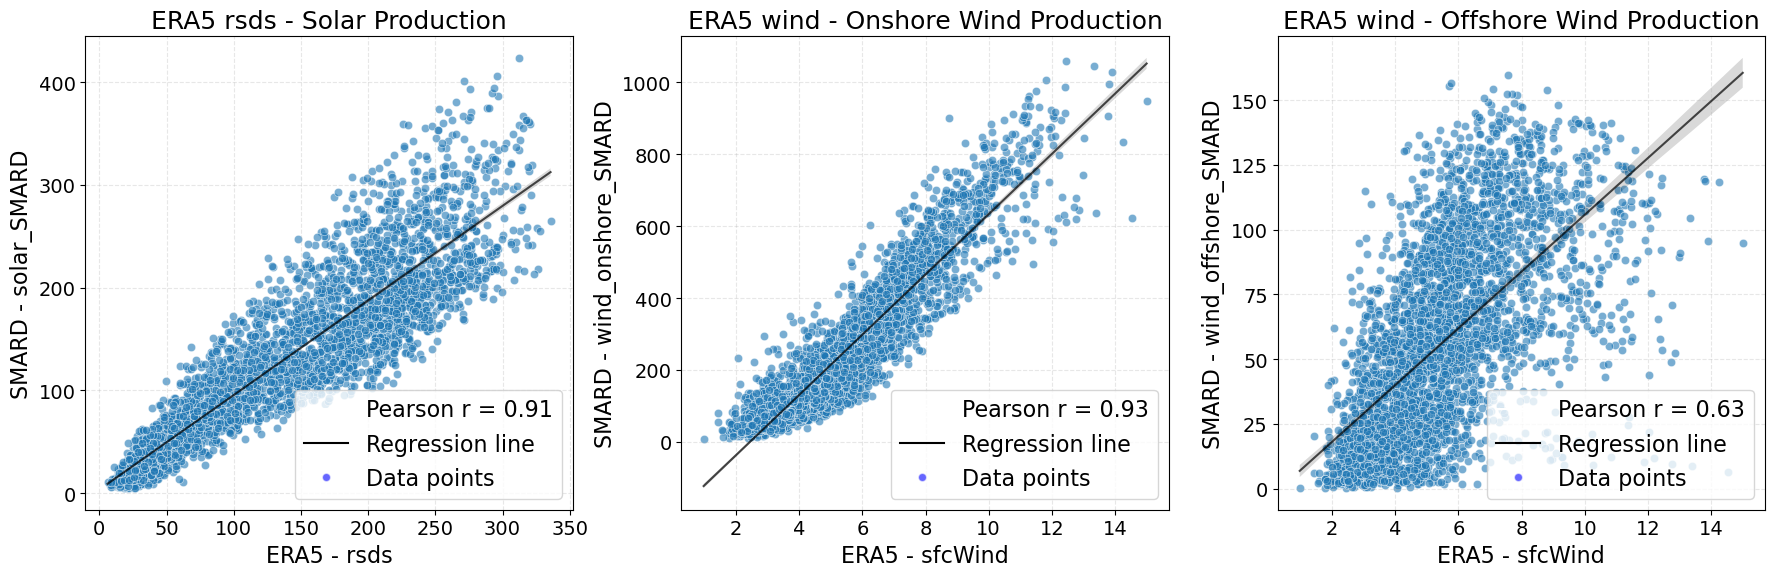

In [52]:
fig, axs = plt.subplots(1, 3, figsize=(18, 6))
plot_specs = [
    ('rsds', 'solar_SMARD', 'ERA5 rsds - Solar Production'),
    ('sfcWind', 'wind_onshore_SMARD', 'ERA5 wind - Onshore Wind Production'),
    ('sfcWind', 'wind_offshore_SMARD', 'ERA5 wind - Offshore Wind Production')
]

for ax, (col_era5, col_smard, title) in zip(axs.flat, plot_specs):
    sns.scatterplot(x=col_era5, y=col_smard, data=df, alpha=0.6, ax=ax)
    
    # Regression line
    sns.regplot(x=col_era5, y=col_smard, data=df, scatter=False, color='black', line_kws={'linewidth': 1.5, 'alpha': 0.7}, ax=ax)
    
    # Pearson r
    r, _ = pearsonr(df[col_smard], df[col_era5])
    
    mae = np.mean(np.abs(df[col_smard] - df[col_era5]))
    rmse = np.sqrt(np.mean((df[col_smard] - df[col_era5])**2))
    mbe = np.mean(df[col_era5] - df[col_smard])


        # Custom legend entries
    legend_elements = [
        Line2D([0], [0], color='w', label=f'Pearson r = {r:.2f}'),  # invisible line, just for text
        Line2D([0], [0], linestyle='-', color='black', label='Regression line'),
        Line2D([0], [0], marker='o', color='w', markerfacecolor='blue', label='Data points', alpha=0.6)
    ]
    ax.legend(handles=legend_elements, loc='lower right', frameon=True)
    ax.set_ylabel(f'SMARD - {col_smard}')
    ax.set_xlabel(f'ERA5 - {col_era5}')
    ax.set_title(f'{title}')
    ax.grid(True, linestyle='--', alpha=0.3)
    # ax.legend(loc='best')

plt.tight_layout()
plt.show()
